In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import arff
import os

In [3]:
file_path = "../dataset/Training Dataset.arff"

with open(file_path, "r") as file:
    data = arff.load(file)

df = pd.DataFrame(
    data["data"],
    columns=[attribute[0] for attribute in data["attributes"]]
)

df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [4]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

Dataset Shape: (11055, 31)

Column Names:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   having_IP_Address            11055 non-null  str  
 1   URL_Length                   11055 non-null  str  
 2   Shortining_Service           11055 non-null  str  
 3   having_At_Symbol             110

In [6]:
for c in df.columns:
    print(f"\n{c}")
    print(df[c].unique())


having_IP_Address
<StringArray>
['-1', '1']
Length: 2, dtype: str

URL_Length
<StringArray>
['1', '0', '-1']
Length: 3, dtype: str

Shortining_Service
<StringArray>
['1', '-1']
Length: 2, dtype: str

having_At_Symbol
<StringArray>
['1', '-1']
Length: 2, dtype: str

double_slash_redirecting
<StringArray>
['-1', '1']
Length: 2, dtype: str

Prefix_Suffix
<StringArray>
['-1', '1']
Length: 2, dtype: str

having_Sub_Domain
<StringArray>
['-1', '0', '1']
Length: 3, dtype: str

SSLfinal_State
<StringArray>
['-1', '1', '0']
Length: 3, dtype: str

Domain_registeration_length
<StringArray>
['-1', '1']
Length: 2, dtype: str

Favicon
<StringArray>
['1', '-1']
Length: 2, dtype: str

port
<StringArray>
['1', '-1']
Length: 2, dtype: str

HTTPS_token
<StringArray>
['-1', '1']
Length: 2, dtype: str

Request_URL
<StringArray>
['1', '-1']
Length: 2, dtype: str

URL_of_Anchor
<StringArray>
['-1', '0', '1']
Length: 3, dtype: str

Links_in_tags
<StringArray>
['1', '-1', '0']
Length: 3, dtype: str

SFH
<Stri

In [8]:
print("Unique target values:")
print(df['Result'].unique())

print("\nTarget distribution:")
print(df['Result'].value_counts())

print(
    df['Result'].value_counts(normalize=True) * 100
)

Unique target values:
<StringArray>
['-1', '1']
Length: 2, dtype: str

Target distribution:
Result
1     6157
-1    4898
Name: count, dtype: int64
Result
1     55.694256
-1    44.305744
Name: proportion, dtype: float64


In [9]:
df.describe(include='all')

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
count,11055,11055,11055,11055,11055,11055,11055,11055,11055,11055,...,11055,11055,11055,11055,11055,11055,11055,11055,11055,11055
unique,2,3,2,2,2,2,3,3,2,2,...,2,2,2,2,3,2,2,3,2,2
top,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,1,1,-1,1,0,1,1
freq,7262,8960,9611,9400,9626,9590,4070,6331,7389,9002,...,8918,10043,5866,7612,5831,8201,9516,6156,9505,6157


In [13]:
#String to numeric conversion of dataset
df = df.apply(pd.to_numeric, errors= 'raise')
print(df.dtypes)
print(df.dtypes.value_counts())
df.describe()

having_IP_Address              int64
URL_Length                     int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic                    int64
Page_Rank                      int64
G

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
count,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,...,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000
mean,0.313795,-0.633198,0.738761,0.700588,0.741474,-0.734962,0.063953,0.250927,-0.336771,0.628584,...,0.613388,0.816915,0.061239,0.377114,0.287291,-0.483673,0.721574,0.344007,0.719584,0.113885
std,0.949534,0.766095,0.673998,0.713598,0.671011,0.678139,0.817518,0.911892,0.941629,0.777777,...,0.789818,0.576784,0.998168,0.926209,0.827733,0.875289,0.692369,0.569944,0.694437,0.993539
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,-1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,1.000000,1.000000,-1.000000,-1.000000,0.000000,-1.000000,1.000000,0.000000,1.000000,-1.000000
50%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,1.000000,-1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,1.000000,1.000000
75%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [26]:
#Check for duplicate records:
d_count = df.duplicated().sum()
print("Count of duplicated: ",d_count)
print("Dataset Shape: ",df.shape)

# Check whether identical features have different target labels
duplicate_groups = (
    df.groupby(list(df.columns[:-1]))['Result']
    .nunique()
)

conflicting_groups = (duplicate_groups > 1).sum()

print("Conflicting duplicate feature groups:", conflicting_groups)


Count of duplicated:  5206
Dataset Shape:  (11055, 31)
Conflicting duplicate feature groups: 64


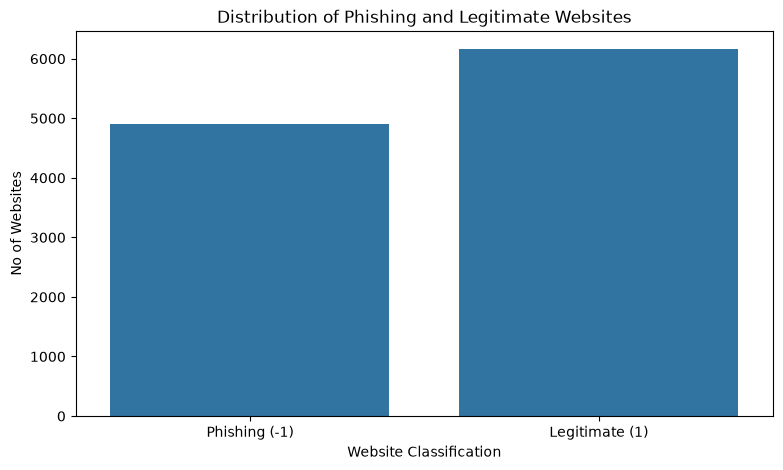

In [18]:
plt.figure(figsize= (9,5))
sns.countplot(data = df,x='Result')
plt.title("Distribution of Phishing and Legitimate Websites")
plt.xlabel('Website Classification')
plt.ylabel('No of Websites')
plt.xticks(ticks=[0,1],labels=['Phishing (-1)','Legitimate (1)'])
plt.show()

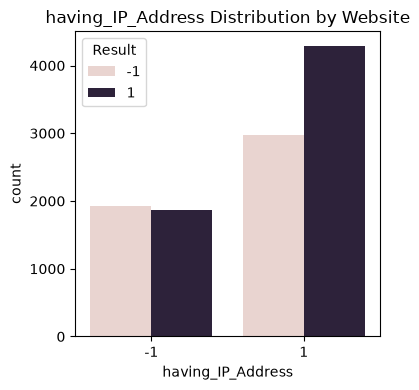

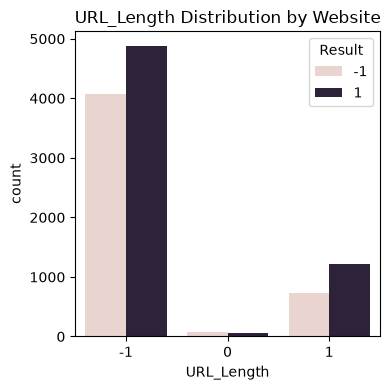

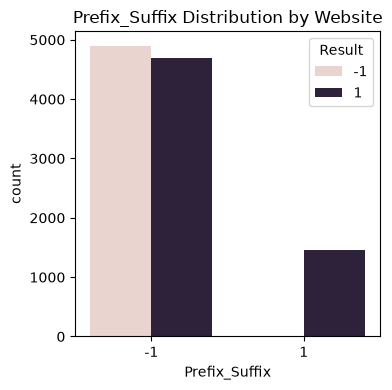

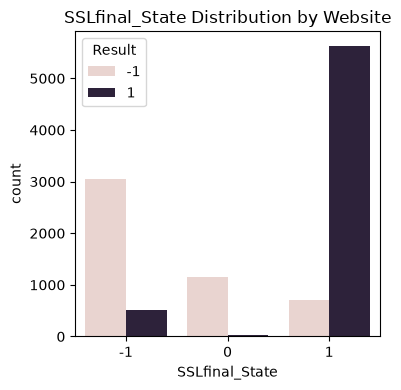

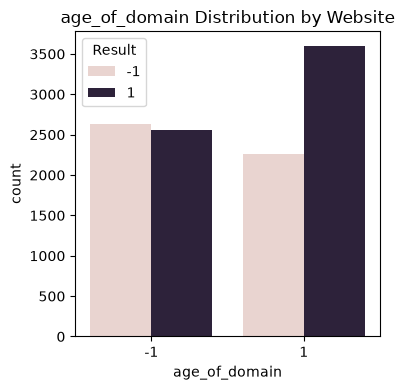

In [20]:
features = ['having_IP_Address','URL_Length','Prefix_Suffix','SSLfinal_State','age_of_domain']
for feature in features:
    plt.figure(figsize=(4,4))
    sns.countplot(data = df,x = feature,hue='Result')
    plt.title(f'{feature} Distribution by Website')
    plt.xlabel(feature)
    plt.ylabel('count')
    plt.tight_layout()
    plt.show()

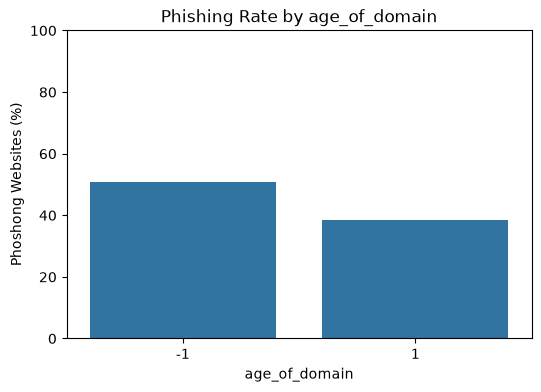

In [23]:
features = [
    'having_IP_Address',
    'URL_Length',
    'Prefix_Suffix',
    'SSLfinal_State',
    'age_of_domain'
]
for f in features:
    phishing_rate = (
        df.groupby(f)['Result'].apply(lambda x: (x == -1).mean()*100)
    )
plt.figure(figsize=(6,4))
sns.barplot(
    x=phishing_rate.index.astype(str),y = phishing_rate.values
)
plt.title(f'Phishing Rate by {feature}')
plt.xlabel(f)
plt.ylabel('Phoshong Websites (%)')
plt.ylim(0,100)
plt.show()

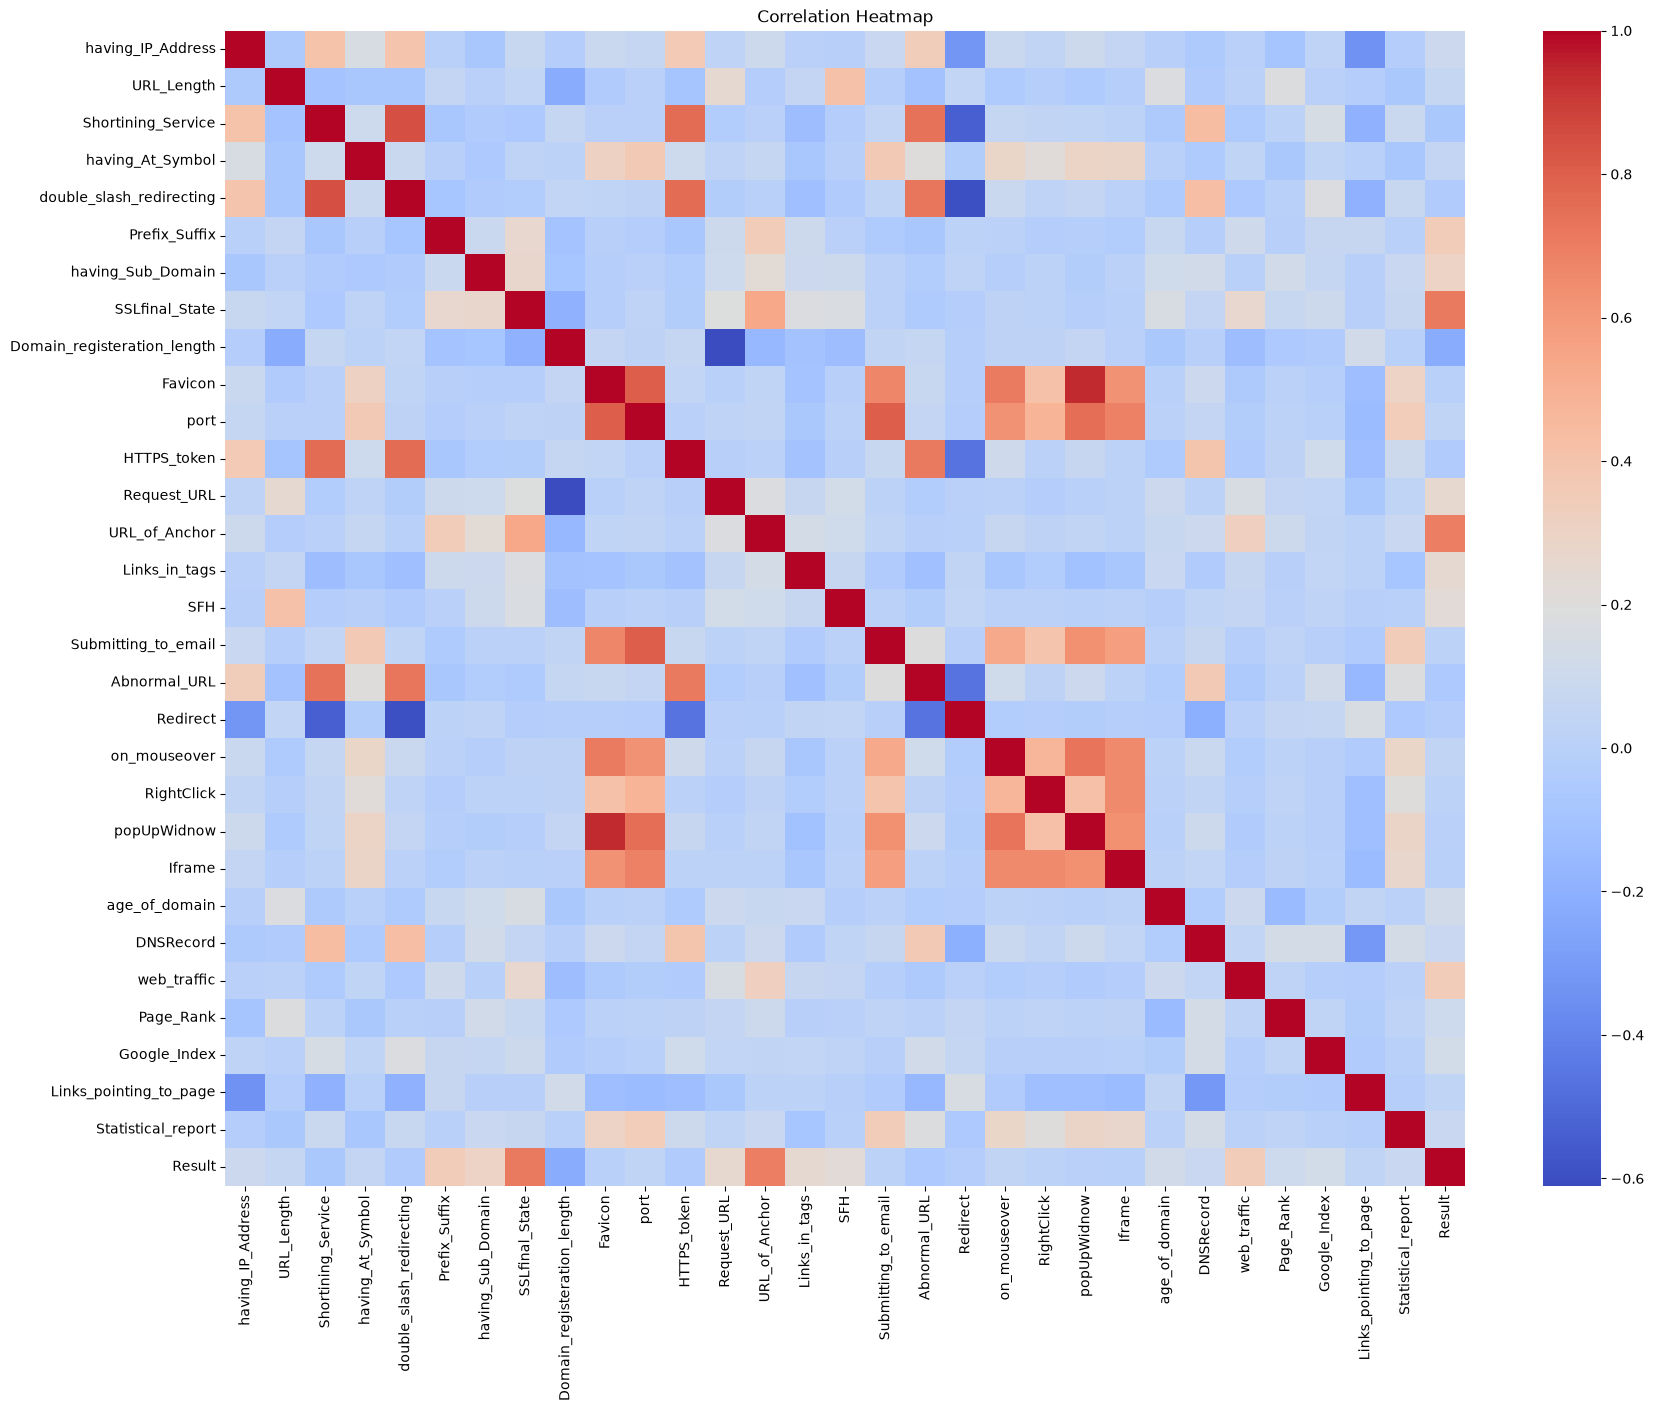

In [24]:
#Correlation Analysis
plt.figure(figsize=(20,15))
correlation = df.corr()
sns.heatmap(correlation,cmap='coolwarm',annot=False)
plt.title("Correlation Heatmap")
plt.show()

In [25]:
target_corr = (df.corr()['Result'].drop('Result').sort_values(key=abs,ascending=False))
print("Feature correlation with Result:")
display(target_corr)


Feature correlation with Result:


SSLfinal_State                 0.714741
URL_of_Anchor                  0.692935
Prefix_Suffix                  0.348606
web_traffic                    0.346103
having_Sub_Domain              0.298323
Request_URL                    0.253372
Links_in_tags                  0.248229
Domain_registeration_length   -0.225789
SFH                            0.221419
Google_Index                   0.128950
age_of_domain                  0.121496
Page_Rank                      0.104645
having_IP_Address              0.094160
Statistical_report             0.079857
DNSRecord                      0.075718
Shortining_Service            -0.067966
Abnormal_URL                  -0.060488
URL_Length                     0.057430
having_At_Symbol               0.052948
on_mouseover                   0.041838
HTTPS_token                   -0.039854
double_slash_redirecting      -0.038608
port                           0.036419
Links_pointing_to_page         0.032574
Redirect                      -0.020113


In [29]:
features = df.drop(columns=['Result']).columns.tolist()
conflicting_groups = (df.groupby(features)['Result'].nunique())
conflicting_groups = conflicting_groups[conflicting_groups > 1]
print("Number pf coflicting groups:",len(conflicting_groups))
conflict_mask = (df.groupby(features)['Result'].transform('nunique') > 1 )
conflict_records = df[conflict_mask]
display(conflict_records.head(20))

Number pf coflicting groups: 64


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
111,1,-1,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,1,-1,1,1,1,-1
112,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,-1,1,0,-1,1,0,1,-1
183,1,-1,1,1,1,-1,-1,1,-1,1,...,1,1,-1,1,0,-1,1,0,1,-1
185,1,-1,1,1,1,-1,-1,1,-1,1,...,1,1,-1,1,0,-1,1,0,1,-1
212,1,-1,1,1,1,-1,-1,-1,1,1,...,1,1,-1,1,1,-1,1,0,1,1
236,1,-1,1,1,1,-1,-1,1,-1,1,...,1,1,-1,1,0,-1,1,0,1,1
242,1,-1,1,1,1,-1,1,1,-1,1,...,1,1,1,-1,0,-1,1,0,1,-1
249,1,-1,1,1,1,-1,-1,-1,1,1,...,1,1,-1,1,1,-1,1,0,1,-1
252,1,-1,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,1,-1,1,1,1,1
262,1,-1,1,1,1,-1,0,-1,1,1,...,1,1,1,-1,1,-1,1,1,1,1


In [31]:
#Removing dupliacte Records
df_clean = df[~conflict_mask].copy()
df_clean = df_clean.drop_duplicates()
print("Original dataset: ",df.shape)
print("Cleaned dataset: ",df_clean)
print("Remaining duplicates: ",df_clean.duplicated().sum())

Original dataset:  (11055, 31)
Cleaned dataset:         having_IP_Address  URL_Length  Shortining_Service  having_At_Symbol  \
0                     -1           1                   1                 1   
1                      1           1                   1                 1   
2                      1           0                   1                 1   
3                      1           0                   1                 1   
4                      1           0                  -1                 1   
...                  ...         ...                 ...               ...   
11032                 -1           1                   1                 1   
11037                  1          -1                  -1                 1   
11048                  1          -1                   1                 1   
11049                 -1          -1                   1                 1   
11054                 -1          -1                   1                 1   

       double_

In [32]:
# Number of records belonging to conflicting groups
print("Conflicting records:", conflict_mask.sum())

# Number of records removed
print("Records removed:",
      len(df) - len(df_clean))

# Class distribution after cleaning
print("\nClass distribution after cleaning:")

print(df_clean['Result'].value_counts())

print("\nClass distribution (%):")

print(
    df_clean['Result']
    .value_counts(normalize=True) * 100
)

Conflicting records: 357
Records removed: 5334

Class distribution after cleaning:
Result
-1    2955
 1    2766
Name: count, dtype: int64

Class distribution (%):
Result
-1    51.651809
 1    48.348191
Name: proportion, dtype: float64


In [33]:
#Remove conflicting feature groups only
df_model = df[~conflict_mask].copy()
print("Dataset shape: ",df_model.shape)
print("\nRemaining conflicting groups: ")
print(df_model.groupby(features)['Result'].nunique().gt(1).sum())
print("\nclass distribution: ")
print(df_model['Result'].value_counts())

Dataset shape:  (10698, 31)

Remaining conflicting groups: 
0

class distribution: 
Result
 1    5945
-1    4753
Name: count, dtype: int64


In [34]:
X = df_model.drop(columns=['Result'])
y = df_model['Result']
print("Feature shape: ",X.shape)
print("Target shape: ",y.shape)
print("\nTarget values: ")
print(y.value_counts())

Feature shape:  (10698, 30)
Target shape:  (10698,)

Target values: 
Result
 1    5945
-1    4753
Name: count, dtype: int64


In [36]:
#Train , Test, Split
from sklearn.model_selection import StratifiedGroupKFold
groups = pd.MultiIndex.from_frame(X).factorize()[0]

sgkf = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42)
train_idx,test_idx = next(sgkf.split(X,y,groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training set: ",X_train.shape)
print("Testing set: ",X_test.shape)
print("\nTraining distribution:")
print(y_train.value_counts(normalize=True)*100)
print("\nTesting distribution:")
print(y_test.value_counts(normalize=True)*100)

Training set:  (8558, 30)
Testing set:  (2140, 30)

Training distribution:
Result
 1    55.573732
-1    44.426268
Name: proportion, dtype: float64

Testing distribution:
Result
 1    55.560748
-1    44.439252
Name: proportion, dtype: float64


Training the Decision Tree


In [37]:
#Training
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(criterion='gini',max_depth=5,random_state=42)
dt_model.fit(X_train,y_train)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [38]:
y_pred = dt_model.predict(X_test)
print("Actual values: ",y_test.values[:10])
print("Predicted values: ",y_pred[:10])

Actual values:  [ 1 -1 -1 -1 -1  1  1  1  1 -1]
Predicted values:  [ 1 -1 -1  1 -1  1  1  1  1 -1]


In [42]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
accuracy = accuracy_score(y_test,y_pred)
print("Model Accuracy: ",accuracy*100,"%")

print("\nClassification Report:")
print(classification_report(y_test,y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))

Model Accuracy:  91.77570093457945 %

Classification Report:
              precision    recall  f1-score   support

          -1       0.94      0.87      0.90       951
           1       0.90      0.96      0.93      1189

    accuracy                           0.92      2140
   macro avg       0.92      0.91      0.92      2140
weighted avg       0.92      0.92      0.92      2140

Confusion Matrix:
[[ 827  124]
 [  52 1137]]


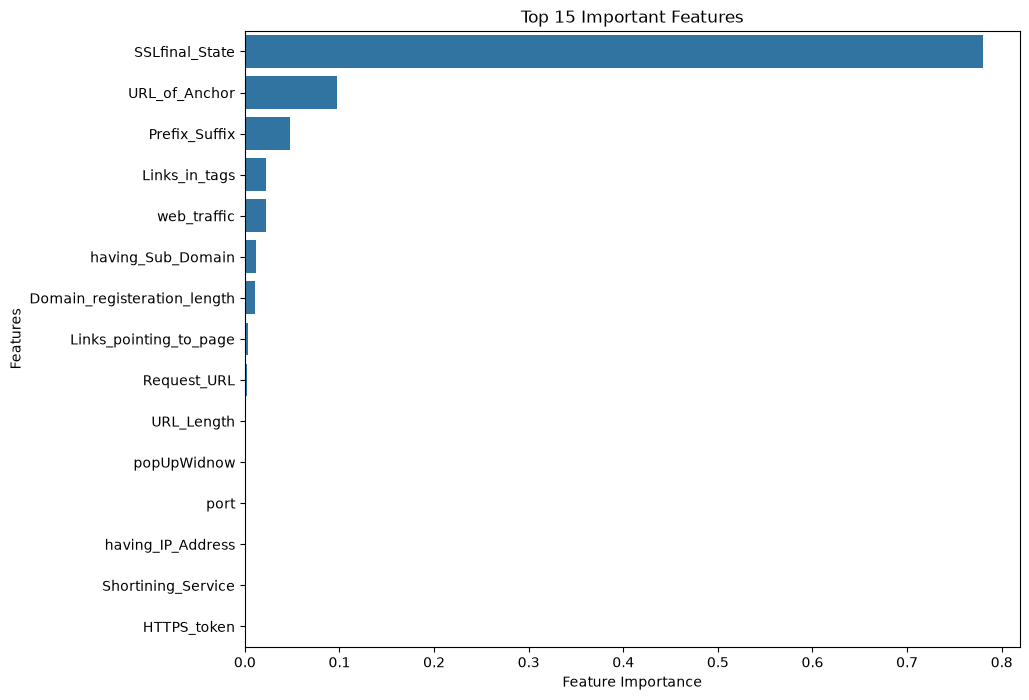

In [44]:
importance = pd.Series(
    dt_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=importance.values[:15],
    y=importance.index[:15]
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.show()

In [47]:
DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

from sklearn.metrics import accuracy_score, recall_score, f1_score

results = []

for depth in [3, 5, 7, 10, 15, None]:

    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        'Max Depth': depth,
        'Accuracy': accuracy_score(y_test, predictions),
        'Phishing Recall': recall_score(
            y_test, predictions, pos_label=-1
        ),
        'Phishing F1': f1_score(
            y_test, predictions, pos_label=-1
        )
    })

results_df = pd.DataFrame(results)

print(results_df)

   Max Depth  Accuracy  Phishing Recall  Phishing F1
0        3.0  0.917757         0.916930     0.908333
1        5.0  0.917757         0.869611     0.903825
2        7.0  0.934112         0.928496     0.926062
3       10.0  0.944393         0.948475     0.938118
4       15.0  0.936916         0.934805     0.929430
5        NaN  0.934579         0.941115     0.927461


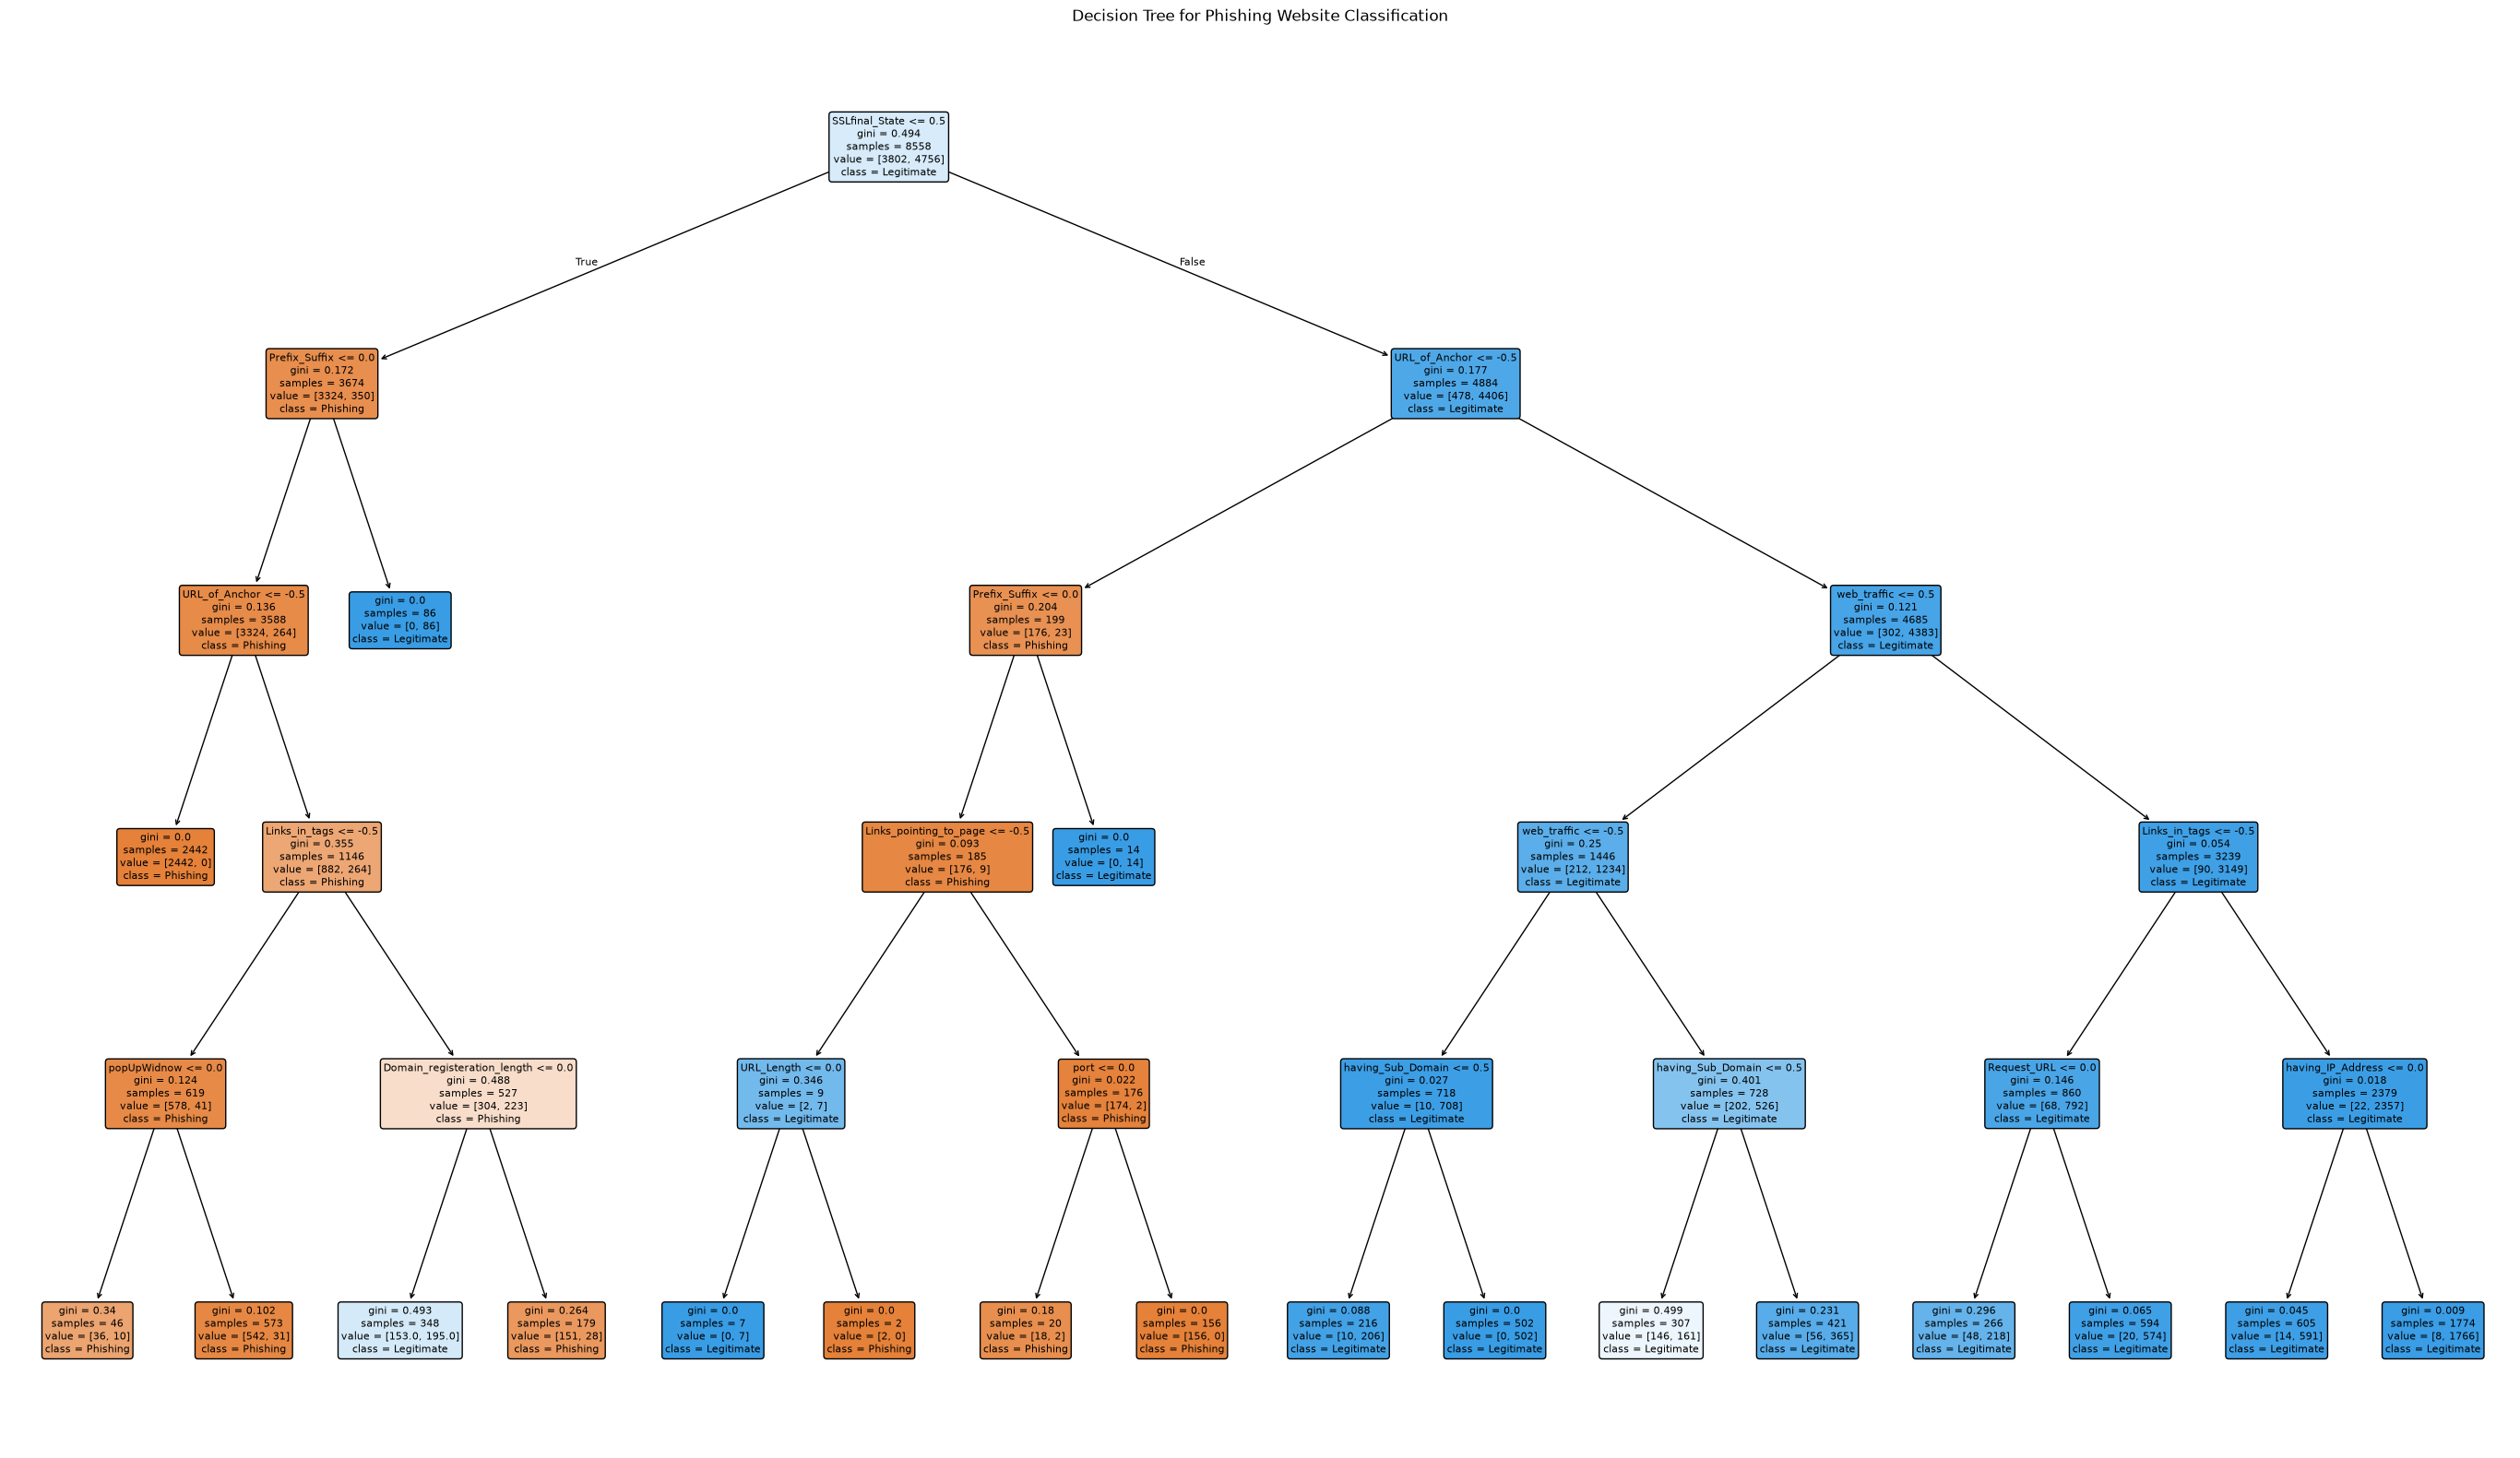

In [43]:
from sklearn.tree import plot_tree
plt.figure(figsize=(35,20))
plot_tree(dt_model,feature_names=X_train.columns,class_names=['Phishing','Legitimate'],filled=True,rounded=True,fontsize=8)
plt.title("Decision Tree for Phishing Website Classification")
plt.show()

In [50]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

dt = DecisionTreeClassifier(random_state=42)

param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [5, 7, 10, 12, 15, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=cv,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Phishing Recall:")
print(grid_search.best_score_)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits
Best Parameters:
{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-Validation Phishing Recall:
0.9859115570518429


In [51]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    recall_score
)

# Get optimized model
best_model = grid_search.best_estimator_

# Predict on test data
y_pred_best = best_model.predict(X_test)

# Accuracy
print("Accuracy:",
      accuracy_score(y_test, y_pred_best) * 100)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

# Phishing recall
print("\nPhishing Recall:",
      recall_score(y_test, y_pred_best, pos_label=-1) * 100)

Accuracy: 93.50467289719626

Classification Report:
              precision    recall  f1-score   support

          -1       0.91      0.94      0.93       951
           1       0.95      0.93      0.94      1189

    accuracy                           0.94      2140
   macro avg       0.93      0.94      0.93      2140
weighted avg       0.94      0.94      0.94      2140


Confusion Matrix:
[[ 898   53]
 [  86 1103]]

Phishing Recall: 94.42691903259727


In [52]:
from sklearn.metrics import accuracy_score, recall_score

# Training predictions
train_pred = best_model.predict(X_train)

# Training performance
train_accuracy = accuracy_score(y_train, train_pred)

train_recall = recall_score(
    y_train,
    train_pred,
    pos_label=-1
)

# Testing performance
test_accuracy = accuracy_score(y_test, y_pred_best)

test_recall = recall_score(
    y_test,
    y_pred_best,
    pos_label=-1
)

print("TRAINING PERFORMANCE")
print("Accuracy:", train_accuracy * 100)
print("Phishing Recall:", train_recall * 100)

print("\nTESTING PERFORMANCE")
print("Accuracy:", test_accuracy * 100)
print("Phishing Recall:", test_recall * 100)

TRAINING PERFORMANCE
Accuracy: 100.0
Phishing Recall: 100.0

TESTING PERFORMANCE
Accuracy: 93.50467289719626
Phishing Recall: 94.42691903259727
